# Avance 3. Modelo de referencia (*baseline*)
**Proyecto Berry-Vision — Clasificación de arándanos defectuosos mediante visión computacional e inteligencia artificial**

**Equipo #6** · Proyecto Integrador MNA · Metodología CRISP-ML(Q), fase *Modeling*

| Integrante | Matrícula |
|---|---|
| José Luis Parada Gutiérrez | A00939669 |
| Kevin Rosario Cota Rodríguez | A01796705 |
| Rolando David Villarreal Martínez | A00609894 |

---
**Objetivos del avance**
- 3.1 Establecer las medidas de calidad del modelo de aprendizaje automático.
- 3.2 Proporcionar un marco de referencia para evaluar y mejorar modelos más avanzados.

**Punto de partida.** El Avance 2 dejó una tabla de **15 características seleccionadas** (Yeo–Johnson + estandarización ajustadas solo con *train*) para 353 recortes, ya particionada 70/15/15 por bloques de captura. Aquí se construye el modelo más simple que sea defendible, se mide qué tan bien funciona y se establece el marco de referencia (métricas, umbral y desempeño mínimo) para evaluar cualquier modelo posterior.

**Preguntas que responde esta libreta**

| # | Pregunta | Sección |
|---|---|---|
| 1 | ¿Qué algoritmo sirve como baseline y por qué? | 3 y 4 |
| 2 | ¿Qué métrica es la adecuada para el negocio? | 2 |
| 3 | ¿Cuál debería ser el desempeño mínimo y el baseline lo alcanza? | 2 y 8 |
| 4 | ¿Qué características importan para el modelo? | 5 |
| 5 | ¿Hay sub/sobreajuste? | 6 |

**Protocolo anti-fuga.** (a) La elección de algoritmo, hiperparámetros y características usa **solo validación cruzada agrupada sobre *train*** (los bloques de captura nunca se parten entre pliegues); (b) *validación* sirve para comprobar sub/sobreajuste y el umbral de decisión; (c) el conjunto de **prueba se toca una sola vez**, en la sección 8.

## 1. Configuración y datos

In [1]:
import os, sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedGroupKFold, learning_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, accuracy_score, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 180)
SEED = 42

# ---- Rutas: Colab (Drive) o ejecución local -------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _in = Path("/content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance2")
    _out = Path("/content/drive/MyDrive/ProyectoIntegrador/Datos/resultados_avance3")
else:
    _in = next((p for p in [Path("../Datos/resultados_avance2"), Path("Datos/resultados_avance2")] if p.exists()),
               Path("../Datos/resultados_avance2"))
    _out = _in.parent / "resultados_avance3"
IN_DIR = Path(os.environ.get("BERRY_IN_DIR", _in))        # tablas del Avance 2 (en el repositorio)
OUT_DIR = Path(os.environ.get("BERRY_OUT_DIR", _out))     # tablas agregadas de este avance
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Entradas:", IN_DIR.resolve(), "| Salidas:", OUT_DIR.resolve(), "| Colab:", IN_COLAB)

Entradas: C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance2 | Salidas: C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance3 | Colab: False


In [2]:
TR, VA, TE = [pd.read_csv(IN_DIR / f"features_seleccionadas_{s}.csv") for s in ("train", "val", "test")]
META = ["crop_id", "grupo", "clase", "particion", "y"]
FEATS = [c for c in TR.columns if c not in META + ["defecto"]]
assert list(TR[FEATS].columns) == list(VA[FEATS].columns) == list(TE[FEATS].columns)
assert not set(TR.grupo) & set(VA.grupo) and not set(TR.grupo) & set(TE.grupo) and not set(VA.grupo) & set(TE.grupo), "bloques repetidos entre particiones"

Xtr, ytr, gtr = TR[FEATS], TR.y.values, TR.grupo.values
Xva, yva = VA[FEATS], VA.y.values
Xte, yte, gte = TE[FEATS], TE.y.values, TE.grupo.values
DEV = pd.concat([TR, VA], ignore_index=True)                  # train + val: solo para el ajuste final (sección 8)
Xdev, ydev, gdev = DEV[FEATS], DEV.y.values, DEV.grupo.values

resumen = pd.DataFrame({"recortes": [len(TR), len(VA), len(TE)], "malos": [ytr.sum(), yva.sum(), yte.sum()],
                        "% malos": [ytr.mean() * 100, yva.mean() * 100, yte.mean() * 100],
                        "bloques": [TR.grupo.nunique(), VA.grupo.nunique(), TE.grupo.nunique()]},
                       index=["train", "val", "test"]).round(1)
display(resumen)
print(f"{len(FEATS)} características: {FEATS}")
n_nan = int(TR[FEATS].isna().sum().sum() + VA[FEATS].isna().sum().sum() + TE[FEATS].isna().sum().sum())
print("Clase positiva = 1 = 'malo' (defectuoso). Valores faltantes:", n_nan)

,recortes,malos,% malos,bloques
train,258,95,36.8,60
val,45,16,35.6,11
test,50,20,40.0,13


15 características: ['rojez_std', 'rojez_p99', 'pct_marron', 'b_p95', 'rojez_p95', 'rojizo_ord', 'grad_p95', 'rugosidad_textura', 'indice_lesion', 'glcm_homogeneidad', 'densidad_bordes', 'nitidez', 'lbp_p6', 'matiz', 'a_medio']
Clase positiva = 1 = 'malo' (defectuoso). Valores faltantes: 0


La clase de interés (*malo*) es **del orden de 4 de cada 10** frutos (≈ 36–40 %) en las tres particiones: desbalance moderado, no extremo. Las particiones comparten la misma distribución, así que el desempeño en validación/prueba es comparable con el de entrenamiento salvo por el ruido propio de conjuntos tan pequeños (≈ 20 frutos malos en cada uno).

## 2. Métrica, costos y desempeño mínimo

### 2.1 ¿Qué métrica?
El sistema decide, fruto por fruto, si el mecanismo de expulsión lo separa. Hay dos errores con costos distintos:

| Error | Qué pasa en la línea | Costo para SOLID / el cliente |
|---|---|---|
| **Falso negativo** (malo que pasa como bueno) | Un fruto defectuoso llega a la caja | Reclamo, rechazo de lote, daño de marca. **Es el error caro.** |
| **Falso positivo** (bueno que se expulsa) | Un fruto sano se desecha | Se pierde el valor de un fruto; molesto en volumen, pero acotado |

Con esto:
- **Exactitud (*accuracy*): descartada como métrica principal.** Con ≈ 4 de cada 10 frutos malos, un modelo que dice "todo bueno" ya acierta ≈ 6 de cada 10 y no detecta nada.
- **Métrica principal de decisión: recall de la clase *malo* (sensibilidad)** sujeta a una precisión mínima, y resumida con **F2** (pondera el recall 4 veces más que la precisión, coherente con que el falso negativo es el error caro).
- **Métrica independiente del umbral para comparar modelos: AP (*average precision*, área bajo la curva precisión–recall).** Es la medida adecuada cuando la clase de interés es la minoritaria y su referencia al azar es la prevalencia (≈ 0.4), no 0.5. Se reporta también ROC-AUC, *balanced accuracy* y MCC como apoyo.

> **Supuesto a confirmar con SOLID México:** que un falso negativo cuesta bastante más que un falso positivo (aquí se asume una razón del orden de 4:1, de allí F2). Si el cliente prefiere no desperdiciar fruto, basta con subir el umbral; la comparación entre modelos (AP) no cambia.

### 2.2 Desempeño mínimo
No existe un histórico cuantitativo de desempeño (hoy la selección es manual y no se mide su tasa de error), por lo que el mínimo se define **por criterio de negocio y por comparación con el azar**, y debe ratificarse con el patrocinador:

| Criterio | Umbral | Razón |
|---|---|---|
| C1. Mejor que el azar | AP > prevalencia, con el límite inferior del IC 95 % por encima de ella | Hay señal real en las características |
| C2. Detección | Recall(*malo*) ≥ **0.80** | De cada 10 frutos defectuosos, se detectan al menos 8 |
| C3. Costo de falsos positivos | Precisión(*malo*) ≥ **0.60** | Por cada 10 frutos expulsados, al menos 6 son realmente defectuosos |

Un baseline que cumpla C1–C3 ya sería una "solución mínima aceptable"; si solo cumple C1, confirma que el problema es viable pero que el baseline no basta para producción.

In [3]:
BETA = 2.0
REC_MIN, PREC_MIN = 0.80, 0.60
PREV = float(ytr.mean())

def metricas(y, p, umbral=0.5):
    # Métricas de clasificación para 'malo' = 1; p = probabilidad (o puntaje) de malo
    yhat = (p >= umbral).astype(int)
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p),
            "recall_malo": recall_score(y, yhat), "precision_malo": precision_score(y, yhat, zero_division=0),
            "F2": fbeta_score(y, yhat, beta=BETA), "bal_acc": balanced_accuracy_score(y, yhat),
            "MCC": matthews_corrcoef(y, yhat), "accuracy": accuracy_score(y, yhat)}

# Validación cruzada agrupada (los bloques de captura no se parten entre pliegues)
def folds(y, g, reps=3, k=5):
    for r in range(reps):
        for tri, tei in StratifiedGroupKFold(k, shuffle=True, random_state=SEED + r).split(np.zeros(len(y)), y, g):
            yield r, tri, tei

def cv_metricas(modelo, X, y, g, reps=3, umbral=0.5):
    filas, oof = [], np.zeros((reps, len(y)))
    for r, tri, tei in folds(y, g, reps):
        m = clone(modelo).fit(X.iloc[tri], y[tri])
        p = m.predict_proba(X.iloc[tei])[:, 1]
        oof[r, tei] = p
        filas.append({"rep": r, **metricas(y[tei], p, umbral)})
    return pd.DataFrame(filas), oof

print(f"Prevalencia de 'malo' en train: {PREV:.3f}  → AP esperado de un modelo al azar ≈ {PREV:.2f}")

Prevalencia de 'malo' en train: 0.368  → AP esperado de un modelo al azar ≈ 0.37


## 3. Piso del azar y referencia de capacidad

El baseline se contrasta con **dos referencias**, ambas con **validación cruzada agrupada 5×3 sobre *train***.

| Modelo | Papel |
|---|---|
| Dummy (prior / estratificado) | Piso: lo que se logra sin ver las características |
| **Regresión logística (L2, pesos balanceados)** | **Baseline propuesto**: lineal, pocos parámetros, estable con unos 250 recortes y 15 variables, interpretable |
| Random forest (solo referencia) | "Termómetro": si un modelo con mucha más capacidad no mejora, la limitante son los datos y no el algoritmo; también sirve para el diagnóstico de sobreajuste de la sección 6 |

In [4]:
CANDIDATOS = {
    "Dummy (prior)":            DummyClassifier(strategy="prior"),
    "Dummy (estratificado)":    DummyClassifier(strategy="stratified", random_state=SEED),
    "Regresión logística":      LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
    "Random forest":            RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=1),
}
filas = []
for nom, mod in CANDIDATOS.items():
    t0 = time.perf_counter()
    cv, _ = cv_metricas(mod, Xtr, ytr, gtr)
    filas.append({"modelo": nom, **cv.drop(columns="rep").mean().to_dict(), "AP_desv": cv.AP.std(), "t_cv_s": time.perf_counter() - t0})
comp = pd.DataFrame(filas).set_index("modelo")
display(comp[["AP", "AP_desv", "ROC_AUC", "recall_malo", "precision_malo", "F2", "bal_acc", "MCC"]].sort_values("AP", ascending=False).round(3))

,AP,AP_desv,ROC_AUC,recall_malo,precision_malo,F2,bal_acc,MCC
modelo,,,,,,,,
Random forest,0.792,0.057,0.823,0.627,0.730,0.644,0.745,0.509
Regresión logística,0.771,0.050,0.821,0.685,0.684,0.683,0.747,0.496
Dummy (estratificado),0.414,0.018,0.572,0.375,0.486,0.392,0.572,0.154
Dummy (prior),0.369,0.017,0.500,0.000,0.000,0.000,0.500,0.000


## 4. Elección del algoritmo baseline

Se elige la **regresión logística regularizada (L2) con pesos de clase balanceados**. La decisión se sostiene en el tipo de problema y de datos, no solo en el número de la tabla anterior (que es solo una referencia, no una búsqueda de algoritmos):

| Aspecto | Hallazgo | Implicación |
|---|---|---|
| **Tipo de datos** | Tabla estructurada de 15 variables numéricas continuas (color, textura, forma), sin faltantes, transformadas (Yeo–Johnson) y estandarizadas | Un modelo lineal las aprovecha directamente; el escalado que necesita ya está hecho |
| **Cantidad de datos** | Unos 250 recortes de entrenamiento (≈ 90 malos) para 15 variables: del orden de 6 observaciones de la clase minoritaria por variable | Poca capacidad es una ventaja: menos varianza, menos riesgo de sobreajuste que un modelo flexible como el random forest |
| **Relevancia de las características** | En el Avance 2 las variables ya fueron filtradas por relevancia y redundancia (\|ρ\| < 0.9) | La colinealidad residual es moderada; L2 la absorbe |
| **Interpretabilidad** | SOLID debe poder explicar *por qué* se expulsa un fruto y qué variable de proceso vigilar | Coeficientes con signo y magnitud comparables (variables estandarizadas) |
| **Salida** | Probabilidad de *malo* | Permite mover el umbral según el costo de FN vs FP sin reentrenar |
| **Desbalance** | ≈ 37–40 % malos | `class_weight="balanced"` evita que el modelo ignore la clase minoritaria |
| **Costo** | Entrena en milisegundos, determinista | Reproducible y fácil de auditar como referencia |

**Qué se esperaría de la alternativa:** si la señal tuviera interacciones fuertes, el random forest mostraría una ventaja clara en AP. Si la diferencia está dentro de la desviación entre pliegues, la regresión logística es el baseline correcto porque aporta lo mismo con la mayor transparencia.

In [5]:
rl, rf = comp.loc["Regresión logística"], comp.loc["Random forest"]
mejor = "Random forest"
dif = comp.loc[mejor, "AP"] - rl.AP
display(Markdown(
    f"- **Regresión logística:** AP = {rl.AP:.3f} ± {rl.AP_desv:.3f} · ROC-AUC = {rl.ROC_AUC:.3f} · recall = {rl.recall_malo:.2f} · precisión = {rl.precision_malo:.2f} · F2 = {rl.F2:.2f}\n"
    f"- **Random forest:** AP = {rf.AP:.3f} ± {rf.AP_desv:.3f} · F2 = {rf.F2:.2f}\n"
    f"- **Mejor AP de la tabla:** {mejor} ({comp.loc[mejor, 'AP']:.3f}); diferencia contra la regresión logística: {dif:+.3f} "
    f"({'dentro' if abs(dif) <= rl.AP_desv else 'fuera'} de una desviación entre repeticiones, {rl.AP_desv:.3f}).\n"
    f"- **Pisos del azar:** AP ≈ {comp.loc['Dummy (prior)', 'AP']:.2f} (= prevalencia); el Dummy estratificado logra F2 = {comp.loc['Dummy (estratificado)', 'F2']:.2f} y MCC = {comp.loc['Dummy (estratificado)', 'MCC']:.2f}."))

- **Regresión logística:** AP = 0.771 ± 0.050 · ROC-AUC = 0.821 · recall = 0.69 · precisión = 0.68 · F2 = 0.68
- **Random forest:** AP = 0.792 ± 0.057 · F2 = 0.64
- **Mejor AP de la tabla:** Random forest (0.792); diferencia contra la regresión logística: +0.021 (dentro de una desviación entre repeticiones, 0.050).
- **Pisos del azar:** AP ≈ 0.37 (= prevalencia); el Dummy estratificado logra F2 = 0.39 y MCC = 0.15.

### 4.1 Ajuste de la regularización (único hiperparámetro)
Se barre `C` (inverso de la regularización) con la misma CV agrupada en *train*. Se elige el **`C` con mayor AP medio en CV**. (La regla de "una desviación estándar" se descartó: con la desviación entre pliegues de ≈ 0.08 elegía `C = 0.001`, un modelo con coeficientes casi nulos que ordena bien pero produce probabilidades pegadas a la prevalencia y hace inservible el umbral.) La curva de validación también sirve para el diagnóstico de sub/sobreajuste de la sección 6.

,AP_train,AP_cv,AP_cv_desv
C,,,
0.001000,0.728,0.737,0.058
0.003162,0.732,0.737,0.058
0.010000,0.737,0.738,0.057
0.031623,0.754,0.746,0.059
0.100000,0.774,0.759,0.052
0.316228,0.789,0.766,0.055
1.000000,0.797,0.771,0.050
3.162278,0.798,0.765,0.054
10.000000,0.799,0.764,0.054


Mejor C por AP en CV = 1; C elegido = 1


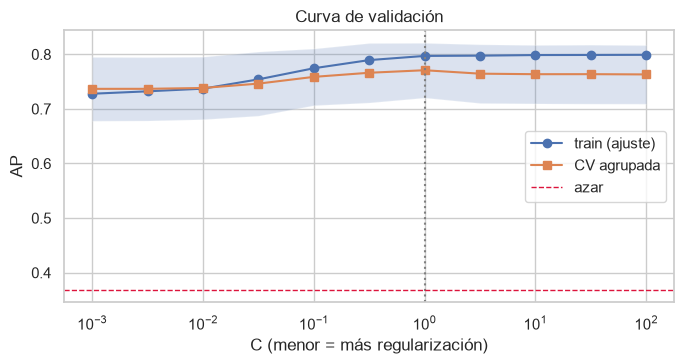

In [6]:
Cs = np.logspace(-3, 2, 11)
LR0 = LogisticRegression(class_weight="balanced", max_iter=5000)
ap_tr, ap_cv = [], []
for C_ in Cs:
    m = clone(LR0).set_params(C=C_)
    cv, _ = cv_metricas(m, Xtr, ytr, gtr)
    ap_cv.append((cv.AP.mean(), cv.AP.std()))
    ap_tr.append(average_precision_score(ytr, m.fit(Xtr, ytr).predict_proba(Xtr)[:, 1]))
vc = pd.DataFrame({"C": Cs, "AP_train": ap_tr, "AP_cv": [a for a, _ in ap_cv], "AP_cv_desv": [s for _, s in ap_cv]}).set_index("C")
mejor_C = vc.AP_cv.idxmax()
C_SEL = float(mejor_C)
display(vc.round(3))
print(f"Mejor C por AP en CV = {mejor_C:.3g}; C elegido = {C_SEL:.3g}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogx(vc.index, vc.AP_train, "o-", label="train (ajuste)"); ax.semilogx(vc.index, vc.AP_cv, "s-", label="CV agrupada")
ax.fill_between(vc.index, vc.AP_cv - vc.AP_cv_desv, vc.AP_cv + vc.AP_cv_desv, alpha=.2)
ax.axvline(C_SEL, color="gray", ls=":"); ax.axhline(PREV, color="crimson", ls="--", lw=1, label="azar")
ax.set_xlabel("C (menor = más regularización)"); ax.set_ylabel("AP"); ax.set_title("Curva de validación"); ax.legend(); plt.tight_layout(); plt.show()

## 5. Importancia de las características

Se usan **tres lentes complementarios** (embebido, de permutación y *wrapper*) y se contrastan con el ranking por filtros del Avance 2. Si coinciden, la conclusión es robusta; si no, se señala por qué.

| Lente | Método | Qué responde |
|---|---|---|
| Embebido | Coeficientes de la regresión logística (con IC por *bootstrap* agrupado) y trayectoria L1 | ¿Qué variables usa el modelo y en qué sentido? |
| Permutación | Caída del AP al barajar cada variable en pliegues no vistos | ¿Qué tanto depende el desempeño de ella? |
| *Wrapper* | RFECV con CV agrupada | ¿Cuántas variables bastan realmente? |

In [7]:
LR = LogisticRegression(C=C_SEL, class_weight="balanced", max_iter=5000).fit(Xtr, ytr)

# (a) Coeficientes con IC 95 % por bootstrap agrupado (se remuestrean bloques completos)
def boot_grupos(g, B, rng):
    u = np.unique(g); idx_por = {k: np.where(g == k)[0] for k in u}
    for _ in range(B):
        yield np.concatenate([idx_por[k] for k in rng.choice(u, len(u), replace=True)])
coefs = []
for ix in boot_grupos(gtr, 300, np.random.default_rng(SEED)):
    if ytr[ix].min() == ytr[ix].max(): continue
    coefs.append(clone(LR).fit(Xtr.iloc[ix], ytr[ix]).coef_[0])
coefs = np.array(coefs)
imp = pd.DataFrame({"coef": LR.coef_[0], "ic_inf": np.percentile(coefs, 2.5, axis=0), "ic_sup": np.percentile(coefs, 97.5, axis=0)}, index=FEATS)
imp["estable"] = ((imp.ic_inf * imp.ic_sup) > 0) & (imp.coef.abs() > 1e-3)                       # el IC no cruza el cero
imp["|coef|"] = imp.coef.abs()
imp = imp.sort_values("|coef|", ascending=False)

# (b) Importancia por permutación en pliegues de CV (se ajusta en el pliegue de entrenamiento, se permuta en el de prueba)
def perm_cv(modelo, X, y, g, reps=2, n_perm=20, seed=SEED):
    r_ = np.random.default_rng(seed); caida = {c: [] for c in X.columns}
    for _, tri, tei in folds(y, g, reps):
        m = clone(modelo).fit(X.iloc[tri], y[tri]); Xt = X.iloc[tei]
        base = average_precision_score(y[tei], m.predict_proba(Xt)[:, 1])
        for c in X.columns:
            v = []
            for _ in range(n_perm):
                Xp = Xt.copy(); Xp[c] = r_.permutation(Xp[c].values)
                v.append(base - average_precision_score(y[tei], m.predict_proba(Xp)[:, 1]))
            caida[c].append(np.mean(v))
    return pd.DataFrame({c: [np.mean(v), np.std(v)] for c, v in caida.items()}, index=["caida_AP", "desv"]).T
perm = perm_cv(LR, Xtr, ytr, gtr)
imp = imp.join(perm)
display(imp[["coef", "ic_inf", "ic_sup", "estable", "caida_AP", "desv"]].round(3))

,coef,ic_inf,ic_sup,estable,caida_AP,desv
b_p95,1.386,0.740,2.131,True,0.238,0.053
nitidez,-0.829,-1.399,-0.227,True,0.043,0.037
rugosidad_textura,0.743,0.043,1.499,True,0.093,0.045
rojez_p95,-0.664,-1.417,0.187,False,0.023,0.011
rojez_std,0.568,-0.010,1.133,False,0.053,0.045
indice_lesion,-0.543,-1.170,-0.025,True,0.020,0.018
glcm_homogeneidad,-0.517,-1.298,0.106,False,0.049,0.027
pct_marron,0.495,0.006,1.125,True,0.046,0.044
a_medio,0.481,-0.016,0.983,False,0.023,0.028
densidad_bordes,0.319,-0.210,1.017,False,0.023,0.016


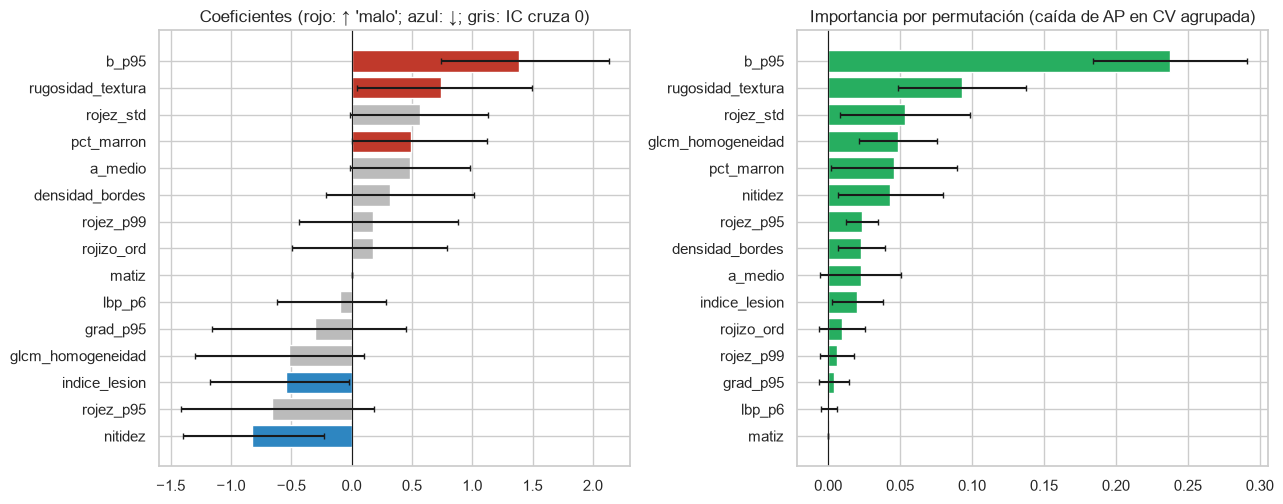

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
o = imp.sort_values("coef")
col = np.where(~o.estable, "#bbbbbb", np.where(o.coef > 0, "#c0392b", "#2e86c1"))
ax[0].barh(o.index, o.coef, color=col, xerr=[o.coef - o.ic_inf, o.ic_sup - o.coef], ecolor="k", capsize=2)
ax[0].axvline(0, color="k", lw=.8); ax[0].set_title("Coeficientes (rojo: ↑ 'malo'; azul: ↓; gris: IC cruza 0)")
p = imp.sort_values("caida_AP")
ax[1].barh(p.index, p.caida_AP, xerr=p.desv, color="#27ae60", capsize=2)
ax[1].axvline(0, color="k", lw=.8); ax[1].set_title("Importancia por permutación (caída de AP en CV agrupada)")
plt.tight_layout(); plt.show()

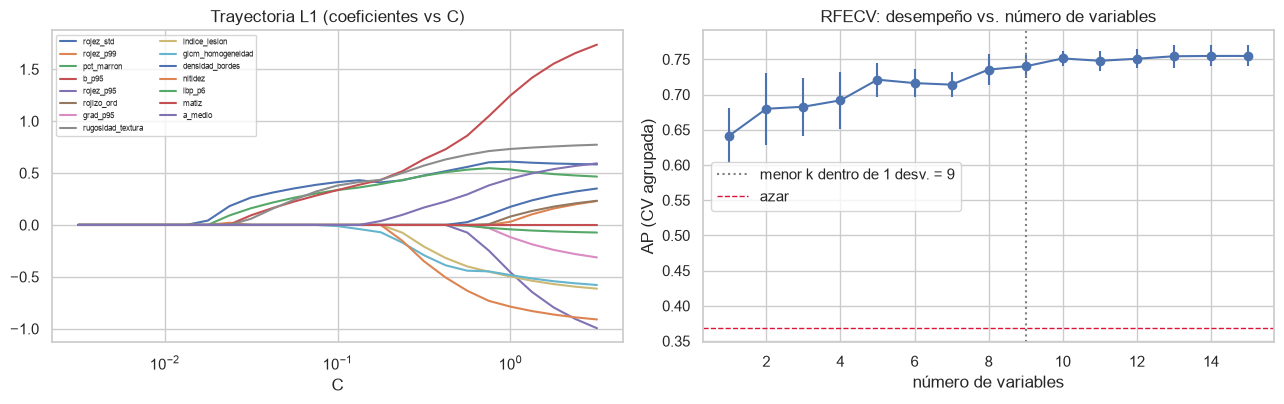

Mejor AP con 14 variables (0.755); con 9 variables se queda dentro de 1 desviación (0.740); con las 15: 0.755


In [9]:
# (c) Trayectoria L1 (embebido): en qué orden entran las variables al relajar la penalización
Cl = np.logspace(-2.5, 0.5, 25); tray = []
for c_ in Cl:
    tray.append(LogisticRegression(penalty="l1", solver="liblinear", C=c_, class_weight="balanced", max_iter=5000).fit(Xtr, ytr).coef_[0])
tray = pd.DataFrame(tray, index=Cl, columns=FEATS)
entrada = {f: (tray.index[(tray[f].abs() > 1e-8).values][0] if (tray[f].abs() > 1e-8).any() else np.inf) for f in FEATS}
orden_l1 = pd.Series(entrada).sort_values()

# (d) Wrapper: RFECV con CV agrupada y AP
sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
rfecv = RFECV(LogisticRegression(C=C_SEL, class_weight="balanced", max_iter=5000), step=1, cv=sgkf, scoring="average_precision", min_features_to_select=1)
rfecv.fit(Xtr, ytr, groups=gtr)
sc = pd.Series(rfecv.cv_results_["mean_test_score"], index=range(1, len(FEATS) + 1)); sd = rfecv.cv_results_["std_test_score"]
k_max = int(sc.idxmax()); k_1sd = int(sc[sc >= sc.max() - sd[k_max - 1]].index.min())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for f in FEATS: ax[0].semilogx(tray.index, tray[f], label=f)
ax[0].set_title("Trayectoria L1 (coeficientes vs C)"); ax[0].set_xlabel("C"); ax[0].legend(fontsize=6, ncol=2)
ax[1].errorbar(sc.index, sc.values, yerr=sd, fmt="o-"); ax[1].axvline(k_1sd, color="gray", ls=":", label=f"menor k dentro de 1 desv. = {k_1sd}")
ax[1].axhline(PREV, color="crimson", ls="--", lw=1, label="azar"); ax[1].set_xlabel("número de variables"); ax[1].set_ylabel("AP (CV agrupada)")
ax[1].set_title("RFECV: desempeño vs. número de variables"); ax[1].legend(); plt.tight_layout(); plt.show()
rfe_rank = pd.Series(rfecv.ranking_, index=FEATS)
print(f"Mejor AP con {k_max} variables ({sc.max():.3f}); con {k_1sd} variables se queda dentro de 1 desviación ({sc[k_1sd]:.3f}); con las {len(FEATS)}: {sc[len(FEATS)]:.3f}")

,rango_coef,rango_permutacion,rango_L1_entrada,rango_RFE,rango_filtros_A2,AUC_MW,rango_medio
b_p95,1.0,1.0,2.0,1,2.0,0.72,1.4
pct_marron,8.0,5.0,2.0,1,1.0,0.72,3.4
rojez_std,5.0,3.0,1.0,1,10.0,0.77,4.0
nitidez,2.0,6.0,8.0,1,5.0,0.66,4.4
rugosidad_textura,3.0,2.0,5.0,1,13.0,0.68,4.8
glcm_homogeneidad,7.0,4.0,6.0,1,11.0,0.31,5.8
indice_lesion,6.0,10.0,8.0,1,4.0,0.68,5.8
a_medio,9.0,9.0,7.0,1,6.0,0.63,6.4
rojez_p95,4.0,7.0,10.0,1,12.0,0.71,6.8
rojez_p99,12.0,12.0,2.0,1,8.0,0.75,7.0


Correlación de Spearman entre los rankings (1 = idénticos):


,rango_coef,rango_permutacion,rango_L1_entrada,rango_RFE,rango_filtros_A2
rango_coef,1.00,0.86,0.55,0.43,0.13
rango_permutacion,0.86,1.00,0.71,0.43,0.08
rango_L1_entrada,0.55,0.71,1.00,0.44,0.18
rango_RFE,0.43,0.43,0.44,1.00,-0.06
rango_filtros_A2,0.13,0.08,0.18,-0.06,1.00


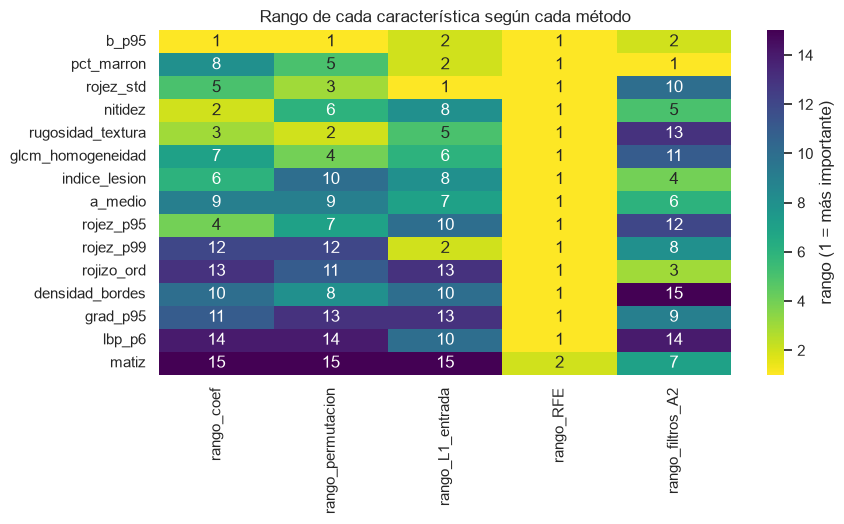

In [10]:
# Concordancia entre lentes y con el ranking por filtros del Avance 2 (ANOVA, χ², información mutua, AUC de Mann–Whitney)
rk = pd.read_csv(IN_DIR / "ranking_caracteristicas.csv", index_col=0)
tabla = pd.DataFrame({
    "rango_coef": imp["|coef|"].rank(ascending=False), "rango_permutacion": imp.caida_AP.rank(ascending=False),
    "rango_L1_entrada": orden_l1.rank(method="min").reindex(FEATS), "rango_RFE": rfe_rank,
    "rango_filtros_A2": rk.loc[FEATS, "rango_consenso"].rank(), "AUC_MW": rk.loc[FEATS, "AUC_MW"]})
RCOLS = [c for c in tabla if c.startswith("rango_")]
tabla["rango_medio"] = tabla[RCOLS].mean(axis=1)
tabla = tabla.sort_values("rango_medio")
display(tabla.round(2))
rho = tabla[RCOLS].corr(method="spearman")
print("Correlación de Spearman entre los rankings (1 = idénticos):"); display(rho.round(2))
fig, ax = plt.subplots(figsize=(9, 5.4))
sns.heatmap(tabla[RCOLS], annot=True, fmt=".0f", cmap="viridis_r", cbar_kws={"label": "rango (1 = más importante)"}, ax=ax)
ax.set_title("Rango de cada característica según cada método"); plt.tight_layout(); plt.show()

In [11]:
# ¿Se pierde algo al quedarse solo con las variables más importantes? (CV agrupada, mismos pliegues)
top_k = list(tabla.index[:k_1sd])
estables = imp.index[imp.estable].tolist()
filas = []
for nom, cols in [(f"Las {len(FEATS)} variables", FEATS), (f"Top {k_1sd} por rango medio", top_k), (f"IC del coef. no cruza 0 ({len(estables)})", estables)]:
    cv, _ = cv_metricas(LogisticRegression(C=C_SEL, class_weight="balanced", max_iter=5000), Xtr[cols], ytr, gtr)
    filas.append({"conjunto": nom, "n": len(cols), "AP": cv.AP.mean(), "AP_desv": cv.AP.std(), "F2": cv.F2.mean(), "recall_malo": cv.recall_malo.mean()})
sub = pd.DataFrame(filas).set_index("conjunto"); display(sub.round(3))
display(Markdown("**Variables más importantes (rango medio):** " + ", ".join(f"`{f}`" for f in tabla.index[:6]) +
                 ".  **Menos relevantes:** " + ", ".join(f"`{f}`" for f in tabla.index[-4:]) + "."))

,n,AP,AP_desv,F2,recall_malo
conjunto,,,,,
Las 15 variables,15,0.771,0.050,0.683,0.685
Top 9 por rango medio,9,0.782,0.054,0.710,0.713
IC del coef. no cruza 0 (5),5,0.748,0.051,0.658,0.661


**Variables más importantes (rango medio):** `b_p95`, `pct_marron`, `rojez_std`, `nitidez`, `rugosidad_textura`, `glcm_homogeneidad`.  **Menos relevantes:** `densidad_bordes`, `grad_p95`, `lbp_p6`, `matiz`.

### 5.1 Cómo leer estos resultados
- **Signo y sentido físico.** Un coeficiente positivo indica que al aumentar la variable (estandarizada) sube la probabilidad de *malo*. Si el signo de alguna variable contradice el conocimiento del dominio (p. ej. que más mancha o más rojez *reduzca* el riesgo), puede deberse a colinealidad o a que la variable capture la sesión de captura y no el defecto; si algún signo contradice el conocimiento del dominio, es señal de colinealidad o de que la variable captura la sesión de captura y no el defecto.
- **Coeficiente vs. permutación.** Un coeficiente grande con poca caída de AP indica redundancia (otra variable cubre su información); una caída grande con coeficiente pequeño es raro y señal de interacciones.
- **Reducir variables.** Si el subconjunto pequeño rinde dentro del ruido de la CV, se prefiere para producción: menos cálculo por fruto en la línea y menos superficie de deriva.

Con los números de esta ejecución:

In [12]:
pos = imp[(imp.estable) & (imp.coef > 0)].index.tolist(); neg = imp[(imp.estable) & (imp.coef < 0)].index.tolist()
inest = imp[~imp.estable].index.tolist()
lista = lambda v: ", ".join(f"`{x}`" for x in v) if v else "ninguna"
top_perm = imp.caida_AP.sort_values(ascending=False).head(3).index.tolist()
display(Markdown(
    f"- **Sentido.** Elevan la probabilidad de *malo* (IC 95 % sin cruzar cero): {lista(pos)}. La reducen: {lista(neg)}. "
    f"Si entre las más influyentes hay variables de brillo o color absoluto (p. ej. percentiles de canal), hay que confirmar con SOLID que no reflejan la iluminación de la captura y no el defecto.\n"
    f"- **Estabilidad.** Solo {len(pos) + len(neg)} de {len(FEATS)} coeficientes son estables ante el remuestreo por bloques; el resto ({len(inest)}) tiene IC que cruza cero y aporta poco por separado, "
    f"probablemente por la correlación entre variables de color/textura que miden cosas parecidas. Por eso el ordenamiento intermedio cambia de un método a otro (correlaciones de Spearman entre rankings de {rho.values[np.triu_indices(len(rho), 1)].min():.2f} a {rho.values[np.triu_indices(len(rho), 1)].max():.2f}), mientras que los primeros lugares sí coinciden.\n"
    f"- **Dependencia del desempeño.** Barajar {', '.join(f'`{x}`' for x in top_perm)} es lo que más baja el AP (caída máx. {imp.caida_AP.max():.3f}); para el resto la caída es comparable a su desviación, es decir, el modelo no depende de ellas individualmente.\n"
    f"- **Parsimonia.** Con 1 variable (`{tabla.index[0]}`) el AP en CV es {sub.iloc[1].AP:.3f} frente a {sub.iloc[0].AP:.3f} con las {len(FEATS)}: {'casi toda la señal de estas características globales está en esa variable; las demás agregan poco.' if sub.iloc[0].AP - sub.iloc[1].AP < 0.05 else 'las demás variables sí aportan una mejora apreciable.'}"))

- **Sentido.** Elevan la probabilidad de *malo* (IC 95 % sin cruzar cero): `b_p95`, `rugosidad_textura`, `pct_marron`. La reducen: `nitidez`, `indice_lesion`. Si entre las más influyentes hay variables de brillo o color absoluto (p. ej. percentiles de canal), hay que confirmar con SOLID que no reflejan la iluminación de la captura y no el defecto.
- **Estabilidad.** Solo 5 de 15 coeficientes son estables ante el remuestreo por bloques; el resto (10) tiene IC que cruza cero y aporta poco por separado, probablemente por la correlación entre variables de color/textura que miden cosas parecidas. Por eso el ordenamiento intermedio cambia de un método a otro (correlaciones de Spearman entre rankings de -0.06 a 0.86), mientras que los primeros lugares sí coinciden.
- **Dependencia del desempeño.** Barajar `b_p95`, `rugosidad_textura`, `rojez_std` es lo que más baja el AP (caída máx. 0.238); para el resto la caída es comparable a su desviación, es decir, el modelo no depende de ellas individualmente.
- **Parsimonia.** Con 1 variable (`b_p95`) el AP en CV es 0.782 frente a 0.771 con las 15: casi toda la señal de estas características globales está en esa variable; las demás agregan poco.

## 6. Sub/sobreajuste

Se aplica el diagnóstico estándar: (1) **brecha entrenamiento vs. CV vs. validación** en varias métricas; (2) **curva de aprendizaje** (¿converge?, ¿más datos ayudan?); (3) **curva de validación** de `C` (sección 4.1); y (4) contraste con un modelo de mayor capacidad (random forest) como "termómetro" del sobreajuste.

| Síntoma | Qué se observa | Diagnóstico |
|---|---|---|
| Subajuste | Desempeño bajo **en entrenamiento y en validación**, curvas juntas y planas | Falta capacidad o información en las variables |
| Sobreajuste | Entrenamiento alto, validación claramente más baja (brecha grande) | Demasiada capacidad para los datos |

In [13]:
def fila(nombre, m, X, y, umbral=0.5):
    return {"modelo": nombre, **metricas(y, m.predict_proba(X)[:, 1], umbral)}
LR_f = clone(LR).fit(Xtr, ytr)
RF_f = clone(CANDIDATOS["Random forest"]).fit(Xtr, ytr)
cv_lr, _ = cv_metricas(LR_f, Xtr, ytr, gtr)
cv_rf, _ = cv_metricas(RF_f, Xtr, ytr, gtr)
filas = []
for nom, m, cv in [("Regresión logística", LR_f, cv_lr), ("Random forest", RF_f, cv_rf)]:
    for conj, X_, y_ in [("train", Xtr, ytr), ("val", Xva, yva)]:
        filas.append({**fila(nom, m, X_, y_), "conjunto": conj})
    filas.append({"modelo": nom, "conjunto": "CV (train)", **cv.drop(columns="rep").mean().to_dict()})
diag = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
display(diag[["AP", "ROC_AUC", "recall_malo", "precision_malo", "F2", "bal_acc", "MCC"]].round(3))
brecha = (diag.xs("train", level=1) - diag.xs("val", level=1))[["AP", "ROC_AUC", "F2", "MCC"]].round(3)
brecha_cv = (diag.xs("train", level=1) - diag.xs("CV (train)", level=1))[["AP", "ROC_AUC", "F2", "MCC"]].round(3)
print("Brecha train − val:"); display(brecha); print("Brecha train − CV:"); display(brecha_cv)
b = brecha.loc["Regresión logística"]; bc = brecha_cv.loc["Regresión logística"]
d_va, d_cv = diag.loc[("Regresión logística", "val")], diag.loc[("Regresión logística", "CV (train)")]
display(Markdown(
    f"**Lectura de la brecha.** En la regresión logística la brecha train–val del ROC-AUC ({b.ROC_AUC:.2f}) es mayor que la train–CV ({bc.ROC_AUC:.2f}). "
    f"La validación fija tiene solo {len(yva)} frutos ({int(yva.sum())} malos): con tan pocos frutos y bloques el desempeño fluctúa mucho de una partición a otra, por lo que la estimación más estable es la de CV agrupada, "
    f"con {len(np.unique(gtr))} bloques y 15 repeticiones de pliegue. La brecha train–CV es pequeña y la curva de aprendizaje converge, de modo que el patrón no es de sobreajuste. Aun así, el AP en validación ({d_va.AP:.2f}) {'es claramente inferior' if d_cv.AP - d_va.AP > 0.1 else 'es similar'} al de CV ({d_cv.AP:.2f}); {'**es una limitación que debe declararse**: con tan pocos bloques no se descarta que esa partición sea más difícil.' if d_cv.AP - d_va.AP > 0.1 else 'sin señales de alerta.'} "
    f"El random forest sí muestra sobreajuste (brecha train–CV de AP = {brecha_cv.loc['Random forest','AP']:.2f})."))

AP  ROC_AUC  recall_malo  precision_malo     F2  bal_acc    MCC
modelo              conjunto                                                                      
Regresión logística train       0.797    0.861        0.737           0.686  0.726    0.770  0.533
                    val         0.523    0.554        0.500           0.421  0.482    0.560  0.117
                    CV (train)  0.771    0.821        0.685           0.684  0.683    0.747  0.496
Random forest       train       0.992    0.995        0.979           0.930  0.969    0.968  0.927
                    val         0.571    0.638        0.312           0.333  0.316    0.484 -0.033
                    CV (train)  0.792    0.823        0.627           0.730  0.644    0.745  0.509

Brecha train − val:


,AP,ROC_AUC,F2,MCC
modelo,,,,
Regresión logística,0.274,0.307,0.244,0.416
Random forest,0.421,0.358,0.652,0.959


Brecha train − CV:


,AP,ROC_AUC,F2,MCC
modelo,,,,
Regresión logística,0.026,0.039,0.043,0.037
Random forest,0.201,0.172,0.325,0.418


**Lectura de la brecha.** En la regresión logística la brecha train–val del ROC-AUC (0.31) es mayor que la train–CV (0.04). La validación fija tiene solo 45 frutos (16 malos): con tan pocos frutos y bloques el desempeño fluctúa mucho de una partición a otra, por lo que la estimación más estable es la de CV agrupada, con 60 bloques y 15 repeticiones de pliegue. La brecha train–CV es pequeña y la curva de aprendizaje converge, de modo que el patrón no es de sobreajuste. Aun así, el AP en validación (0.52) es claramente inferior al de CV (0.77); **es una limitación que debe declararse**: con tan pocos bloques no se descarta que esa partición sea más difícil. El random forest sí muestra sobreajuste (brecha train–CV de AP = 0.20).

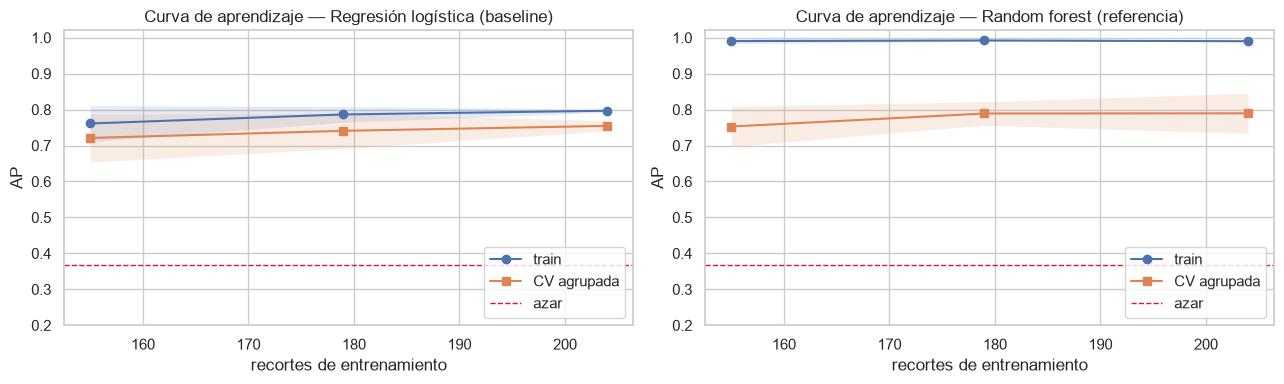

,n,AP_train,AP_cv,brecha
3,155,0.761,0.721,0.040
4,179,0.786,0.741,0.046
5,204,0.797,0.755,0.042


In [14]:
tam = np.linspace(0.4, 1.0, 6)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (nom, mod) in zip(ax, [("Regresión logística (baseline)", LR), ("Random forest (referencia)", CANDIDATOS["Random forest"])]):
    n, tr_s, cv_s = learning_curve(clone(mod), Xtr, ytr, groups=gtr, train_sizes=tam, scoring="average_precision",
                                   cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), shuffle=False)[:3]
    a.plot(n, tr_s.mean(1), "o-", label="train"); a.fill_between(n, tr_s.mean(1) - tr_s.std(1), tr_s.mean(1) + tr_s.std(1), alpha=.15)
    a.plot(n, cv_s.mean(1), "s-", label="CV agrupada"); a.fill_between(n, cv_s.mean(1) - cv_s.std(1), cv_s.mean(1) + cv_s.std(1), alpha=.15)
    a.axhline(PREV, color="crimson", ls="--", lw=1, label="azar"); a.set_ylim(0.2, 1.02)
    a.set_title(f"Curva de aprendizaje — {nom}"); a.set_xlabel("recortes de entrenamiento"); a.set_ylabel("AP"); a.legend(loc="lower right")
    if mod is LR: lc = pd.DataFrame({"n": n, "AP_train": tr_s.mean(1), "AP_cv": cv_s.mean(1)}).assign(brecha=lambda d: d.AP_train - d.AP_cv)
plt.tight_layout(); plt.show()
lc = lc.dropna()   # tamaños donde algún pliegue quedó con una sola clase
display(lc.round(3))

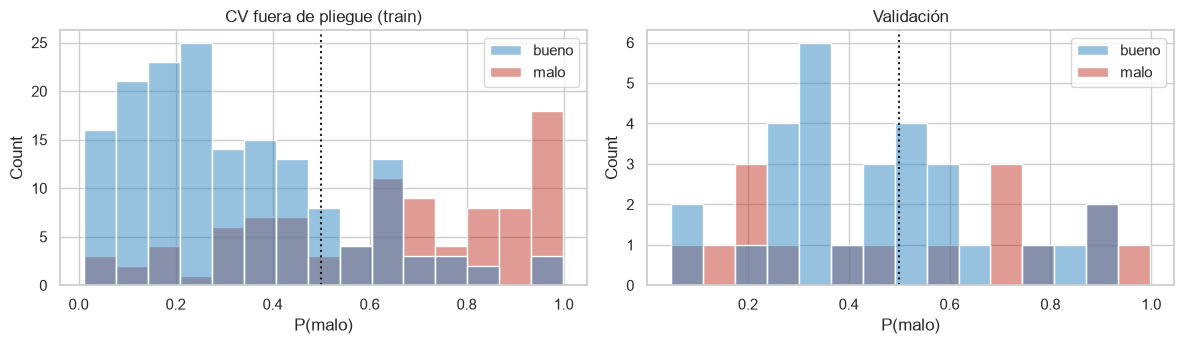

In [15]:
# Distribución de la probabilidad predicha por clase: CV (fuera de pliegue) y validación
_, oof = cv_metricas(LR, Xtr, ytr, gtr, reps=1)
p_oof, p_va = oof[0], LR_f.predict_proba(Xva)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for a, (t, p, y) in zip(ax, [("CV fuera de pliegue (train)", p_oof, ytr), ("Validación", p_va, yva)]):
    sns.histplot(x=p, hue=np.where(y == 1, "malo", "bueno"), bins=15, multiple="layer", ax=a, palette={"bueno": "#2e86c1", "malo": "#c0392b"})
    a.axvline(0.5, color="k", ls=":"); a.set_title(t); a.set_xlabel("P(malo)")
plt.tight_layout(); plt.show()

## 7. Umbral de decisión

El umbral 0.5 no tiene por qué ser el que conviene al negocio. Se elige con las **predicciones fuera de pliegue de *train*** (sin mirar validación ni prueba) y se **comprueba en validación**.

**Regla:** el umbral más alto (el que menos fruto sano expulsa) que aún da **recall(*malo*) ≥ 0.80** en predicciones fuera de pliegue. No se maximiza F2 directamente porque con ≈ 4 de cada 10 malos la regla trivial "todo es malo" ya obtiene F2 ≈ 0.74 (recall 1, precisión 0.37): F2 sola premia marcar todo. Por eso F2 siempre se lee junto con la precisión y contra la fila `todo_malo` de la sección 8. También se muestra qué precisión cuesta cada nivel de recall, que es la conversación que hay que tener con SOLID.

Umbral elegido (mayor umbral con recall OOF ≥ 0.8): 0.383


recall_malo  precision_malo     F2  bal_acc    MCC  accuracy
conjunto    umbral                                                                            
train (OOF) 0.5                         0.653           0.667  0.655    0.731  0.465     0.752
            0.38 (recall ≥ 0.80)        0.779           0.561  0.723    0.712  0.408     0.694
val         0.5                         0.500           0.421  0.482    0.560  0.117     0.578
            0.38 (recall ≥ 0.80)        0.625           0.400  0.562    0.554  0.104     0.533

,umbral,precisión alcanzable
recall objetivo,,
0.70,0.480,0.650
0.80,0.383,0.578
0.85,0.335,0.550
0.90,0.262,0.498
0.95,0.157,0.429


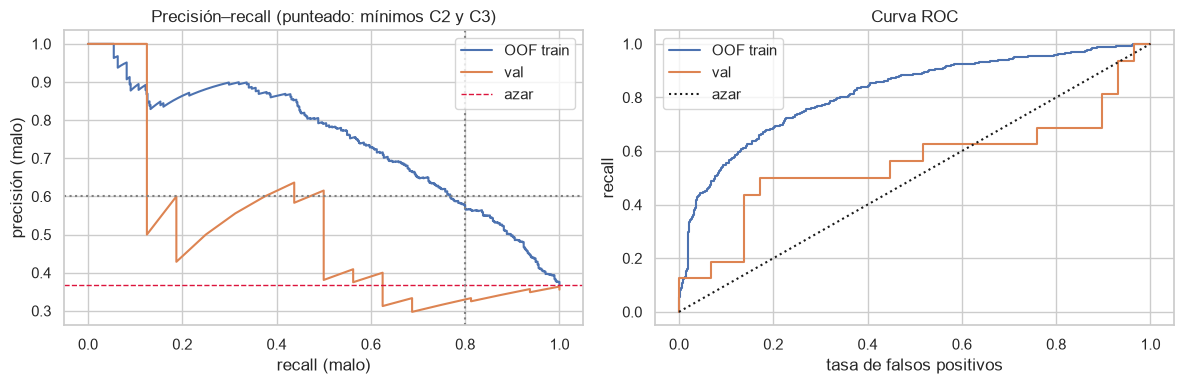

In [16]:
_, oof3 = cv_metricas(LR, Xtr, ytr, gtr, reps=5)
pr, rc, th = precision_recall_curve(np.tile(ytr, 5), oof3.ravel())
U = float(th[rc[:-1] >= REC_MIN][-1])                  # umbral más alto con recall OOF ≥ 0.80
print(f"Umbral elegido (mayor umbral con recall OOF ≥ {REC_MIN}): {U:.3f}")
filas = []
for nom, p, y in [("train (OOF)", oof3[0], ytr), ("val", p_va, yva)]:
    for u_nom, u in [("0.5", 0.5), (f"{U:.2f} (recall ≥ 0.80)", U)]:
        filas.append({"conjunto": nom, "umbral": u_nom, **metricas(y, p, u)})
display(pd.DataFrame(filas).set_index(["conjunto", "umbral"])[["recall_malo", "precision_malo", "F2", "bal_acc", "MCC", "accuracy"]].round(3))

# Precisión alcanzable para cada recall objetivo (OOF de train)
obj = []
for r_ in (0.7, 0.8, 0.85, 0.9, 0.95):
    ok = rc[:-1] >= r_
    obj.append({"recall objetivo": r_, "umbral": th[ok][-1] if ok.any() else np.nan, "precisión alcanzable": pr[:-1][ok].max() if ok.any() else np.nan})
display(pd.DataFrame(obj).set_index("recall objetivo").round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rc, pr, label="OOF train"); pv, rv, _ = precision_recall_curve(yva, p_va); ax[0].plot(rv, pv, label="val")
ax[0].axhline(PREV, color="crimson", ls="--", lw=1, label="azar"); ax[0].axvline(REC_MIN, color="gray", ls=":"); ax[0].axhline(PREC_MIN, color="gray", ls=":")
ax[0].set_xlabel("recall (malo)"); ax[0].set_ylabel("precisión (malo)"); ax[0].set_title("Precisión–recall (punteado: mínimos C2 y C3)"); ax[0].legend()
fpr, tpr, _ = roc_curve(np.tile(ytr, 5), oof3.ravel()); ax[1].plot(fpr, tpr, label="OOF train"); fv, tv, _ = roc_curve(yva, p_va); ax[1].plot(fv, tv, label="val")
ax[1].plot([0, 1], [0, 1], "k:", label="azar"); ax[1].set_xlabel("tasa de falsos positivos"); ax[1].set_ylabel("recall"); ax[1].set_title("Curva ROC"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Evaluación final en prueba (una sola vez)

Con el algoritmo, `C` y el umbral ya fijados en train, el modelo se reajusta con **train + validación** y se evalúa **una única vez** en el conjunto de prueba (bloques de captura no vistos). Como son del orden de 50 frutos, dan intervalos amplios, se reportan **IC 95 % por *bootstrap* de bloques** y se contrasta con los pisos del azar y con los criterios C1–C3.

,prueba,ic_inf,ic_sup,dummy_prior,todo_malo
AP,0.729,0.480,0.915,0.4,0.400
ROC_AUC,0.782,0.631,0.928,0.5,0.500
recall_malo,0.850,0.600,1.000,0.0,1.000
precision_malo,0.586,0.361,0.800,0.0,0.400
F2,0.780,0.569,0.935,0.0,0.769
bal_acc,0.725,0.597,0.875,0.5,0.500
MCC,0.447,0.186,0.741,0.0,0.000
accuracy,0.700,0.556,0.857,0.6,0.400


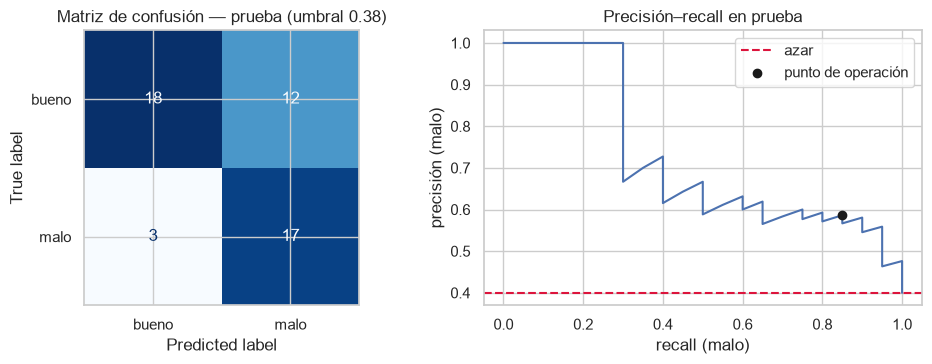

Prueba: 17 malos detectados, 3 malos que pasan (FN), 12 buenos expulsados (FP), 18 buenos correctamente aceptados.


In [17]:
FINAL = clone(LR).fit(Xdev, ydev)
p_te = FINAL.predict_proba(Xte)[:, 1]
m_te = metricas(yte, p_te, U)

# Bootstrap de bloques para IC 95 %
bs = []
for ix in boot_grupos(gte, 1000, np.random.default_rng(SEED)):
    if yte[ix].min() == yte[ix].max(): continue
    bs.append(metricas(yte[ix], p_te[ix], U))
bs = pd.DataFrame(bs)
ic = bs.quantile([.025, .975]).T.rename(columns={.025: "ic_inf", .975: "ic_sup"})
final = pd.DataFrame({"prueba": pd.Series(m_te)}).join(ic)

# Referencias: Dummy (prior) ajustado en train+val y evaluado en prueba, y regla trivial 'todo malo'
dm = DummyClassifier(strategy="prior").fit(Xdev, ydev)
final["dummy_prior"] = pd.Series(metricas(yte, dm.predict_proba(Xte)[:, 1], 0.5))
final["todo_malo"] = pd.Series(metricas(yte, np.ones(len(yte))))
display(final.loc[["AP", "ROC_AUC", "recall_malo", "precision_malo", "F2", "bal_acc", "MCC", "accuracy"]].round(3))

cm = confusion_matrix(yte, (p_te >= U).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ConfusionMatrixDisplay(cm, display_labels=["bueno", "malo"]).plot(ax=ax[0], colorbar=False, cmap="Blues"); ax[0].set_title(f"Matriz de confusión — prueba (umbral {U:.2f})")
pt, rt, _ = precision_recall_curve(yte, p_te); ax[1].plot(rt, pt); ax[1].axhline(yte.mean(), color="crimson", ls="--", label="azar")
ax[1].scatter([m_te["recall_malo"]], [m_te["precision_malo"]], color="k", zorder=3, label="punto de operación")
ax[1].set_xlabel("recall (malo)"); ax[1].set_ylabel("precisión (malo)"); ax[1].set_title("Precisión–recall en prueba"); ax[1].legend(); plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Prueba: {tp} malos detectados, {fn} malos que pasan (FN), {fp} buenos expulsados (FP), {tn} buenos correctamente aceptados.")

In [18]:
c1 = bool(final.loc["AP", "ic_inf"] > yte.mean())
c2 = bool(m_te["recall_malo"] >= REC_MIN)
c3 = bool(m_te["precision_malo"] >= PREC_MIN)
crit = pd.DataFrame({
    "criterio": ["C1. AP > azar (IC inf. > prevalencia)", f"C2. Recall(malo) ≥ {REC_MIN}", f"C3. Precisión(malo) ≥ {PREC_MIN}"],
    "valor": [f"AP = {m_te['AP']:.3f} (IC {final.loc['AP','ic_inf']:.3f}–{final.loc['AP','ic_sup']:.3f}) vs azar {yte.mean():.3f}",
              f"{m_te['recall_malo']:.3f} (IC {final.loc['recall_malo','ic_inf']:.2f}–{final.loc['recall_malo','ic_sup']:.2f})",
              f"{m_te['precision_malo']:.3f} (IC {final.loc['precision_malo','ic_inf']:.2f}–{final.loc['precision_malo','ic_sup']:.2f})"],
    "cumple": ["Sí" if c1 else "No", "Sí" if c2 else "No", "Sí" if c3 else "No"]}).set_index("criterio")
display(crit)

,valor,cumple
criterio,,
C1. AP > azar (IC inf. > prevalencia),AP = 0.729 (IC 0.480–0.915) vs azar 0.400,Sí
C2. Recall(malo) ≥ 0.8,0.850 (IC 0.60–1.00),Sí
C3. Precisión(malo) ≥ 0.6,0.586 (IC 0.36–0.80),No


## 9. Resumen, conclusiones y siguientes pasos

In [19]:
rl = comp.loc["Regresión logística"]
d_tr, d_va, d_cv = diag.loc[("Regresión logística", "train")], diag.loc[("Regresión logística", "val")], diag.loc[("Regresión logística", "CV (train)")]
d_rf_tr, d_rf_cv = diag.loc[("Random forest", "train")], diag.loc[("Random forest", "CV (train)")]
gap_lr, gap_rf = d_tr.AP - d_cv.AP, d_rf_tr.AP - d_rf_cv.AP
fi = lc.iloc[-1]
if d_cv.AP < 0.6:        estado = "**subajuste**"
elif gap_lr > 0.15:      estado = "**sobreajuste**"
else:                    estado = "**ajuste razonable, sin sobreajuste apreciable**"
n_ok = int(c1) + int(c2) + int(c3)
veredicto = {3: "**cumple los tres criterios mínimos**: es una solución mínima aceptable.",
             2: "**cumple dos de los tres criterios**: hay señal y utilidad parcial; queda una brecha por cerrar frente al mínimo.",
             1: "**solo supera el azar**: el problema es viable, pero con estas características no alcanza el mínimo operativo.",
             0: "**no supera el azar**: los datos/características no bastan; habría que revisar adquisición y etiquetado."}[n_ok]
cumple = ", ".join(f"{k.split('.')[0]}: {v}" for k, v in crit.cumple.items())
txt = f'''
**Algoritmo.** Regresión logística L2 con pesos balanceados (C = {C_SEL:.3g}), sobre {len(FEATS)} características estructuradas y estandarizadas. En CV agrupada su AP es **{rl.AP:.3f} ± {rl.AP_desv:.3f}** frente a {comp.loc["Dummy (prior)","AP"]:.2f} del azar; \
el mejor candidato de la comparación fue *{mejor}* (AP {comp.loc[mejor,"AP"]:.3f}, diferencia {dif:+.3f}).

**Características.** Las más influyentes (rango medio entre coeficientes, permutación, L1, RFE y filtros del Avance 2) son {", ".join(f"`{f}`" for f in tabla.index[:5])}. \
{len(estables)} de {len(FEATS)} coeficientes tienen IC 95 % que no cruza cero. RFECV muestra que con **{k_1sd}** variables el AP ({sc[k_1sd]:.3f}) queda dentro de una desviación del mejor ({sc.max():.3f}); el subconjunto "top {k_1sd}" alcanza AP {sub.iloc[1].AP:.3f} vs {sub.iloc[0].AP:.3f} con todas.

**Sub/sobreajuste.** AP train / CV / val = {d_tr.AP:.3f} / {d_cv.AP:.3f} / {d_va.AP:.3f} (brecha train–CV = {gap_lr:.3f}); la curva de aprendizaje termina con brecha {fi.brecha:.3f}. Diagnóstico: {estado}. \
El random forest, con más capacidad, tiene brecha train–CV de {gap_rf:.3f} y AP en CV de {d_rf_cv.AP:.3f}.

**Métrica.** Recall de *malo* con precisión mínima (falso negativo = error caro), AP para comparar modelos (clase minoritaria, ≈ 4 de cada 10) y F2 como resumen, siempre leída contra la regla trivial "todo malo" (F2 = {final.loc["F2","todo_malo"]:.2f}). Se descarta *accuracy* porque "todo bueno" ya acierta {1 - yte.mean():.0%} en prueba.

**Desempeño mínimo y resultado en prueba (n = {len(yte)}).** Con umbral {U:.2f}: recall = **{m_te["recall_malo"]:.2f}**, precisión = **{m_te["precision_malo"]:.2f}**, F2 = {m_te["F2"]:.2f}, AP = {m_te["AP"]:.2f} (IC {final.loc["AP","ic_inf"]:.2f}–{final.loc["AP","ic_sup"]:.2f}) vs {yte.mean():.2f} del azar. Criterios → {cumple}. \
El baseline {veredicto}
'''
display(Markdown(txt))


**Algoritmo.** Regresión logística L2 con pesos balanceados (C = 1), sobre 15 características estructuradas y estandarizadas. En CV agrupada su AP es **0.771 ± 0.050** frente a 0.37 del azar; el mejor candidato de la comparación fue *Random forest* (AP 0.792, diferencia +0.021).

**Características.** Las más influyentes (rango medio entre coeficientes, permutación, L1, RFE y filtros del Avance 2) son `b_p95`, `pct_marron`, `rojez_std`, `nitidez`, `rugosidad_textura`. 5 de 15 coeficientes tienen IC 95 % que no cruza cero. RFECV muestra que con **9** variables el AP (0.740) queda dentro de una desviación del mejor (0.755); el subconjunto "top 9" alcanza AP 0.782 vs 0.771 con todas.

**Sub/sobreajuste.** AP train / CV / val = 0.797 / 0.771 / 0.523 (brecha train–CV = 0.026); la curva de aprendizaje termina con brecha 0.042. Diagnóstico: **ajuste razonable, sin sobreajuste apreciable**. El random forest, con más capacidad, tiene brecha train–CV de 0.201 y AP en CV de 0.792.

**Métrica.** Recall de *malo* con precisión mínima (falso negativo = error caro), AP para comparar modelos (clase minoritaria, ≈ 4 de cada 10) y F2 como resumen, siempre leída contra la regla trivial "todo malo" (F2 = 0.77). Se descarta *accuracy* porque "todo bueno" ya acierta 60% en prueba.

**Desempeño mínimo y resultado en prueba (n = 50).** Con umbral 0.38: recall = **0.85**, precisión = **0.59**, F2 = 0.78, AP = 0.73 (IC 0.48–0.92) vs 0.40 del azar. Criterios → C1: Sí, C2: Sí, C3: No. El baseline **cumple dos de los tres criterios**: hay señal y utilidad parcial; queda una brecha por cerrar frente al mínimo.


### 9.1 Limitaciones y puntos a confirmar
1. **Tamaño de la muestra:** del orden de 50 frutos de prueba (≈ 20 malos) dan intervalos amplios; conviene ampliar el etiquetado y reportar siempre IC.
2. **Confusión con la sesión de captura:** los bloques agrupan la iluminación; validar con fotos de otra sesión/día antes de producción.
3. **Costos reales:** ratificar con SOLID la razón FN:FP y los mínimos C2/C3 para fijar el umbral definitivo.

In [20]:
# Exportación de resultados agregados y modelo (sin imágenes)
import joblib
comp.round(4).to_csv(OUT_DIR / "comparacion_modelos_cv.csv")
imp.join(tabla[RCOLS + ["rango_medio"]]).round(4).to_csv(OUT_DIR / "importancia_caracteristicas.csv")
diag.round(4).to_csv(OUT_DIR / "diagnostico_sobreajuste.csv")
final.round(4).to_csv(OUT_DIR / "metricas_prueba.csv")
pd.DataFrame({"crop_id": TE.crop_id, "grupo": TE.grupo, "y": yte, "p_malo": p_te, "pred": (p_te >= U).astype(int)}).to_csv(OUT_DIR / "predicciones_prueba.csv", index=False)
joblib.dump({"modelo": FINAL, "features": FEATS, "umbral": U, "C": C_SEL, "criterios": {"recall_min": REC_MIN, "precision_min": PREC_MIN}}, OUT_DIR / "baseline_logreg.joblib")
json.dump({"C": C_SEL, "umbral": U, "n_train": int(len(TR)), "n_val": int(len(VA)), "n_test": int(len(TE)), "seed": SEED}, open(OUT_DIR / "config_baseline.json", "w"), indent=1)
print("Guardado en", OUT_DIR.resolve(), "→", sorted(p.name for p in OUT_DIR.iterdir()))

Guardado en C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance3 → ['baseline_logreg.joblib', 'comparacion_modelos_cv.csv', 'config_baseline.json', 'diagnostico_sobreajuste.csv', 'importancia_caracteristicas.csv', 'metricas_prueba.csv', 'predicciones_prueba.csv']
